<a href="https://colab.research.google.com/github/Alaxooy/visualisation/blob/main/visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/ACME Stores.csv')

# Display basic information and the first few rows
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 352047 entries, 0 to 352046
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Customer_ID         352047 non-null  object 
 1   Product_SKU         352047 non-null  object 
 2   Gender              352047 non-null  object 
 3   Age                 352047 non-null  object 
 4   Job                 352047 non-null  int64  
 5   City_Type           352047 non-null  object 
 6   Residence_Duration  352047 non-null  object 
 7   Marital_Status      352047 non-null  int64  
 8   Main_Category       352047 non-null  int64  
 9   Secondary_Category  240861 non-null  float64
 10  Tertiary_Category   106803 non-null  float64
 11  Spend_Amount        352047 non-null  int64  
dtypes: float64(2), int64(4), object(6)
memory usage: 32.2+ MB
None


,Customer_ID,Product_SKU,Gender,Age,Job,City_Type,Residence_Duration,Marital_Status,Main_Category,Secondary_Category,Tertiary_Category,Spend_Amount
0,29ef7f09b0db34244455037afd30b1c3,584cd5ddf46b52d9590f4717278b92a8,female,0-17,10,A,2,0,3,NaN,NaN,8370
1,29ef7f09b0db34244455037afd30b1c3,e77d1fe77248e826c87cda61bcd3787f,female,0-17,10,A,2,0,12,NaN,NaN,1422
2,29ef7f09b0db34244455037afd30b1c3,a9e332ca149064815c6fffed2f570f06,female,0-17,10,A,2,0,12,14.0,NaN,1057
3,08d5ef2bbbc54522624aa3d5b20375a7,b1d3a3d24a86bf99a6f8251c3844de10,male,55+,16,C,4+,0,8,NaN,NaN,7969
4,598c89bd4557b2d6a971cbf99bebeab6,b4cfef5decf96297db0001c35df588a6,male,46-50,7,B,2,1,1,15.0,NaN,15854


In [2]:
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_info = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percentage
})

display(missing_info.sort_values(by='Missing Values', ascending=False))

,Missing Values,Percentage (%)
Tertiary_Category,245244,69.662289
Secondary_Category,111186,31.582715
Customer_ID,0,0.000000
Product_SKU,0,0.000000
Age,0,0.000000
Gender,0,0.000000
Job,0,0.000000
City_Type,0,0.000000
Marital_Status,0,0.000000
Residence_Duration,0,0.000000


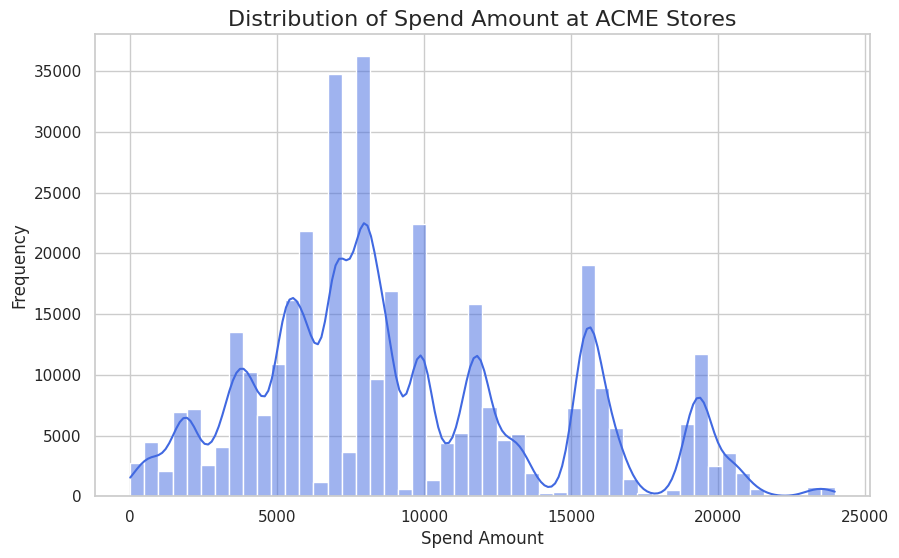

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# Create a figure
plt.figure(figsize=(10, 6))

# Plot the distribution of Spend_Amount
sns.histplot(data=df, x='Spend_Amount', kde=True, bins=50, color='royalblue')

# Set labels and title
plt.title('Distribution of Spend Amount at ACME Stores', fontsize=16)
plt.xlabel('Spend Amount', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Show the plot
plt.show()

/tmp/ipykernel_708/630115690.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


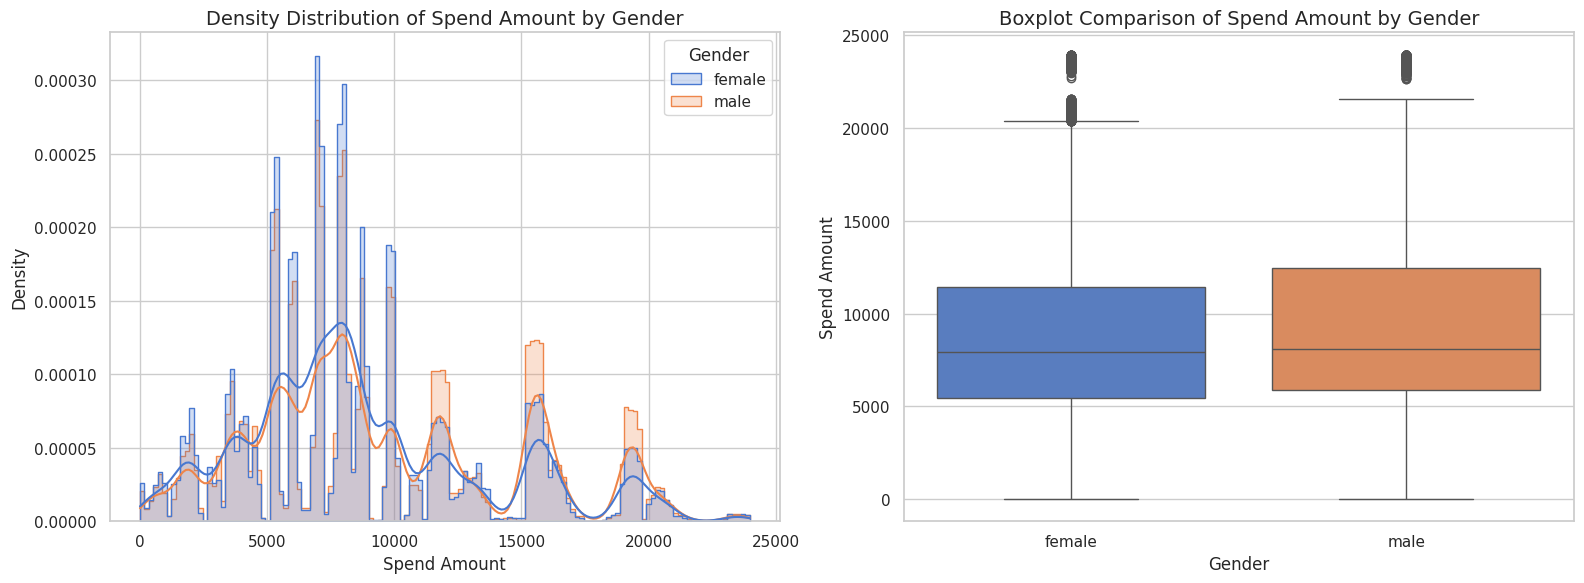

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create subplots to show the distribution in two informative ways
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Overlapping Kernel Density Estimate (KDE) plot
sns.histplot(
    data=df,
    x='Spend_Amount',
    hue='Gender',
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    palette='muted',
    ax=axes[0]
)
axes[0].set_title('Density Distribution of Spend Amount by Gender', fontsize=14)
axes[0].set_xlabel('Spend Amount', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)

# Plot 2: Boxplot for comparing medians and quartiles
sns.boxplot(
    data=df,
    x='Gender',
    y='Spend_Amount',
    palette='muted',
    ax=axes[1]
)
axes[1].set_title('Boxplot Comparison of Spend Amount by Gender', fontsize=14)
axes[1].set_xlabel('Gender', fontsize=12)
axes[1].set_ylabel('Spend Amount', fontsize=12)

plt.tight_layout()
plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


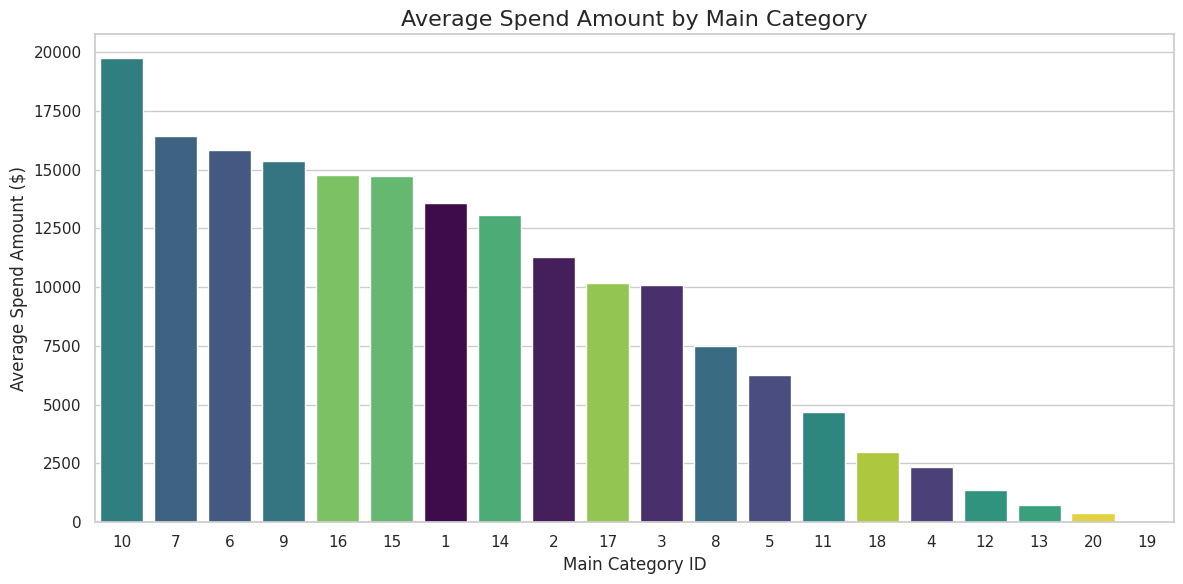

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average spend for each Main_Category
category_spend = df.groupby('Main_Category')['Spend_Amount'].mean().reset_index()
# Sort categories by average spend in descending order for better visualization
category_spend = category_spend.sort_values(by='Spend_Amount', ascending=False)

# Set the visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create a bar plot
sns.barplot(
    data=category_spend,
    x='Main_Category',
    y='Spend_Amount',
    hue='Main_Category',
    palette='viridis',
    legend=False,
    order=category_spend['Main_Category']
)

# Set labels and title
plt.title('Average Spend Amount by Main Category', fontsize=16)
plt.xlabel('Main Category ID', fontsize=12)
plt.ylabel('Average Spend Amount ($)', fontsize=12)

plt.tight_layout()
plt.show()